In [212]:
import os 
import sys
from dataclasses import dataclass
sys.path.append(os.path.join(os.path.dirname("__file__"), '..'))

import numpy as np
import scipy
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt

import skfem
import gmsh
import meshio
from src.utils import *

In [205]:

node, ele, *_ = make_dom_2(h=1)
x = node[ele]
ele[2: 5]

array([[656, 688, 748],
       [668, 691, 750],
       [677, 683, 767]], dtype=int32)

In [141]:
J = np.stack((x[:, 1]-x[:,0], x[:, 2]-x[:,0]), -1) 
# [N, dim, dim] : each [[dx/dxi dx/deta], [dy/dxi, dy/deta]]

detJ = np.linalg.det(J)
invJ = np.linalg.inv(J)


In [208]:
mass = np.bincount(
    ele.ravel(),
    weights=np.repeat((abs(detJ) / 2) / 3, 3),
    minlength=len(node),
)
mass.shape

(783,)

In [ ]:
edges = np.sort(np.concatenate([ele[:, [0, 1]], ele[:, [1, 2]],
                                ele[:, [2, 0]]]), axis=1)
edges, nc = np.unique(edges, axis=0, return_counts=True)
edge_bc = edges[nc == 1]
node_bc = node[np.unique(edge_bc)]

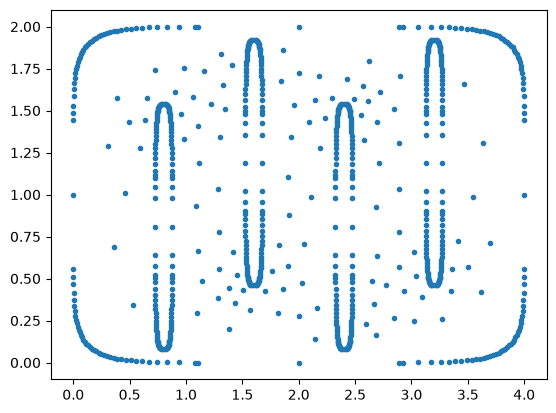

In [230]:
plt.plot(node[:, 0], node[:, 1], '.')